# Principal Component Analysis of the US Treasury Yield Curve

**Objective.** Yields of different maturities move together, but not identically. This notebook asks whether a small number of independent factors can describe most of the daily movements of the US Treasury yield curve, and whether these factors have a clear economic meaning.

**Approach.** We use daily Treasury yields for nine maturities (3M to 30Y), clean the data and compute daily yield changes. PCA is applied to the changes rather than to the levels, because levels are highly persistent. The PCA is run on the covariance matrix of the changes: we study the explained variance and the loadings of each component, and we interpret the first three as Level, Slope and Curvature.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

In [2]:
# Import the dataset from GitHub

url = "https://raw.githubusercontent.com/fujiapple852/yield/master/data/us_treasury_yield_curve_history.csv"

df = pd.read_csv(url)

# Convert the date column to datetime format
df["date"] = pd.to_datetime(df["date"])

# Sort observations by date
df = df.sort_values("date")

# Select the period from 1990 to 2023
df = df[(df["date"] >= "1990-01-01") &
        (df["date"] <= "2023-12-31")]

# Display the top observations
df.head(10)


,date,1M,2M,3M,4M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
0,1990-01-02,NaN,NaN,7.83,NaN,7.89,7.81,7.87,7.90,7.87,7.98,7.94,NaN,8.00
1,1990-01-03,NaN,NaN,7.89,NaN,7.94,7.85,7.94,7.96,7.92,8.04,7.99,NaN,8.04
2,1990-01-04,NaN,NaN,7.84,NaN,7.90,7.82,7.92,7.93,7.91,8.02,7.98,NaN,8.04
3,1990-01-05,NaN,NaN,7.79,NaN,7.85,7.79,7.90,7.94,7.92,8.03,7.99,NaN,8.06
4,1990-01-08,NaN,NaN,7.79,NaN,7.88,7.81,7.90,7.95,7.92,8.05,8.02,NaN,8.09
5,1990-01-09,NaN,NaN,7.80,NaN,7.82,7.78,7.91,7.94,7.92,8.05,8.02,NaN,8.10
6,1990-01-10,NaN,NaN,7.75,NaN,7.78,7.77,7.91,7.95,7.92,8.00,8.03,NaN,8.11
7,1990-01-11,NaN,NaN,7.80,NaN,7.80,7.77,7.91,7.95,7.94,8.01,8.04,NaN,8.11
8,1990-01-12,NaN,NaN,7.74,NaN,7.81,7.76,7.93,7.98,7.99,8.07,8.10,NaN,8.17
9,1990-01-16,NaN,NaN,7.89,NaN,7.99,7.92,8.10,8.13,8.11,8.18,8.20,NaN,8.25


In [3]:

# Display the dataset information
df.info()

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the selected dates
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

<class 'pandas.core.frame.DataFrame'>
Index: 8506 entries, 0 to 8505
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    8506 non-null   datetime64[ns]
 1   1M      5607 non-null   float64       
 2   2M      1302 non-null   float64       
 3   3M      8503 non-null   float64       
 4   4M      300 non-null    float64       
 5   6M      8506 non-null   float64       
 6   1Y      8506 non-null   float64       
 7   2Y      8506 non-null   float64       
 8   3Y      8506 non-null   float64       
 9   5Y      8506 non-null   float64       
 10  7Y      8506 non-null   float64       
 11  10Y     8506 non-null   float64       
 12  20Y     7567 non-null   float64       
 13  30Y     7512 non-null   float64       
dtypes: datetime64[ns](1), float64(13)
memory usage: 996.8 KB
Dataset shape: (8506, 14)
First date: 1990-01-02 00:00:00
Last date: 2023-12-29 00:00:00


## 2) Data Cleaning

We now select the 9 maturities for teh PCA analysis

In [4]:
# Select the maturities for the PCA analysis

maturities = ["3M", "6M", "1Y", "2Y", "3Y",
              "5Y", "7Y", "10Y", "30Y"]

# Create a dataframe containing only the selected maturities
df_pca = df.set_index("date")[maturities].copy()


# Convert all yield values to numeric format
for col in maturities:
    df_pca[col]= pd.to_numeric(df_pca[col], errors="coerce")

df_pca.head()

,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,30Y
date,,,,,,,,,
1990-01-02,7.83,7.89,7.81,7.87,7.90,7.87,7.98,7.94,8.00
1990-01-03,7.89,7.94,7.85,7.94,7.96,7.92,8.04,7.99,8.04
1990-01-04,7.84,7.90,7.82,7.92,7.93,7.91,8.02,7.98,8.04
1990-01-05,7.79,7.85,7.79,7.90,7.94,7.92,8.03,7.99,8.06
1990-01-08,7.79,7.88,7.81,7.90,7.95,7.92,8.05,8.02,8.09


2.1 Missing value analysis

In [5]:
# Missing values by maturity
print(df_pca.isna().sum(), "\nTotal missing:", df_pca.isna().sum().sum())

3M       3
6M       0
1Y       0
2Y       0
3Y       0
5Y       0
7Y       0
10Y      0
30Y    994
dtype: int64 
Total missing: 997


In [6]:
# Calculate the total number of missing values
print("Total missing values:", df_pca.isna().sum().sum())


Total missing values: 997


2.2 Interpolation for NaN

In [7]:
# Fill only short internal gaps (max 2 consecutive days, no extrapolation) and drop the rest.
# Long gaps (e.g. the missing 30Y history) are NOT interpolated: it would create artificial changes.
df_clean = df_pca.interpolate(method="linear",limit_area="inside").dropna()

print("Initial observations:", len(df_pca))
print("Final observations:", len(df_clean))
print("Removed observations:", len(df_pca) - len(df_clean))

Initial observations: 8506
Final observations: 8506
Removed observations: 0


## 3) Exploratory Data Analysis

In [8]:
df_clean.describe()

,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,30Y
count,8506.000000,8506.000000,8506.000000,8506.000000,8506.000000,8506.000000,8506.000000,8506.000000,8506.000000
mean,2.679489,2.810676,2.927416,3.192941,3.387066,3.745660,4.032167,4.251213,4.767504
std,2.294794,2.325102,2.316671,2.323227,2.272247,2.167891,2.088132,1.995126,1.827358
min,0.000000,0.020000,0.040000,0.090000,0.100000,0.190000,0.360000,0.520000,0.990000
25%,0.180000,0.320000,0.490000,0.880000,1.270000,1.742500,2.170000,2.530000,3.120000
50%,2.250000,2.420000,2.540000,2.910000,3.180000,3.580000,3.850000,4.120000,4.700000
75%,4.980000,5.090000,5.060000,5.090000,5.230000,5.520000,5.720000,5.810000,6.030000
max,8.260000,8.490000,8.640000,9.050000,9.110000,9.100000,9.120000,9.090000,9.180000


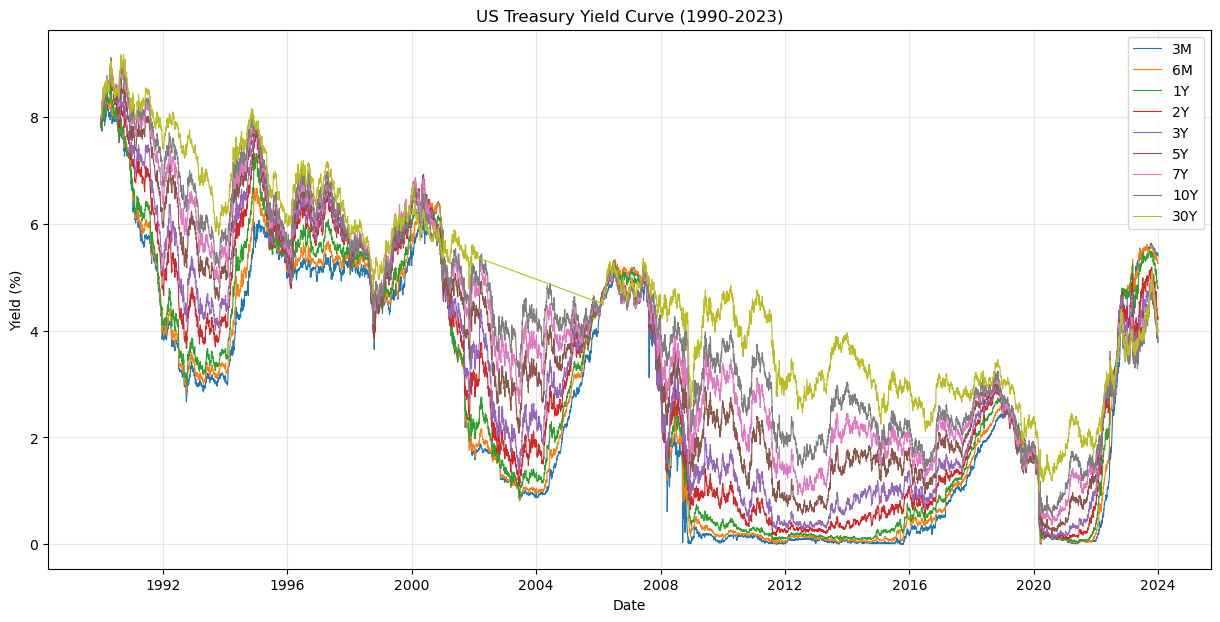

In [9]:

# Plot the historical evolution of the selected maturities

plt.figure(figsize=(15, 7))

for maturity in maturities:
    plt.plot(df_clean.index, df_clean[maturity],
             label=maturity, linewidth=0.8)

plt.title("US Treasury Yield Curve (1990-2023)")
plt.xlabel("Date")
plt.ylabel("Yield (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


3.1 Correlation between maturities

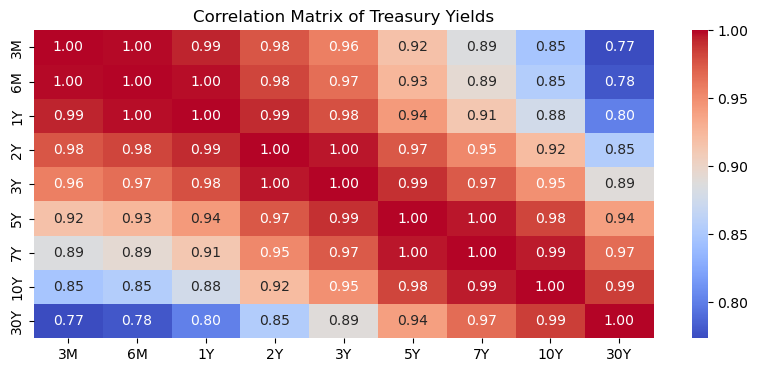

In [10]:
correlation_matrix=df_clean.corr()

plt.figure(figsize=(10,4))

sns.heatmap(correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f")

plt.title("Correlation Matrix of Treasury Yields")
plt.show()

As expected, the correlation is strong among maturities because they tend to be influenced by the same macroeconomic factors and monetary policy decisions.

# 4) Daily variation

Why we use daily changes instead of levels

This is one of the most important methodological decisions of the project. We do not apply PCA directly to the **levels** of the yields, but to their **daily changes**:

$$\Delta y_t^{(i)} = y_t^{(i)} - y_{t-1}^{(i)}$$

where:

- $y_t^{(i)}$ is the yield of maturity $i$ on day $t$;
- $y_{t-1}^{(i)}$ is the yield of the same maturity on the previous day.

In this way we study **how the curve moves**, rather than simply analysing the level of interest rates.

In [11]:

# Daily changes in yields (percentage points)
yield_changes = df_clean.diff()

# Drop changes that span more than 5 calendar days (e.g. across a removed gap)
gap_days = df_clean.index.to_series().diff().dt.days
yield_changes = yield_changes[gap_days <= 5].dropna()
print("Observations:", len(yield_changes))
yield_changes.describe()

Observations: 8505


,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,30Y
count,8505.000000,8505.000000,8505.000000,8505.000000,8505.000000,8505.000000,8505.000000,8505.000000,8505.000000
mean,-0.000286,-0.000309,-0.000355,-0.000428,-0.000457,-0.000474,-0.000482,-0.000477,-0.000467
std,0.047379,0.041194,0.045089,0.056020,0.058887,0.061375,0.061279,0.058363,0.050140
min,-0.810000,-0.490000,-0.600000,-0.570000,-0.500000,-0.460000,-0.530000,-0.510000,-0.330000
25%,-0.010000,-0.010000,-0.020000,-0.030000,-0.030000,-0.030000,-0.040000,-0.030000,-0.030000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000864
75%,0.010000,0.010000,0.020000,0.030000,0.030000,0.030000,0.030000,0.030000,0.030000
max,0.760000,0.750000,0.520000,0.380000,0.400000,0.410000,0.420000,0.390000,0.320000


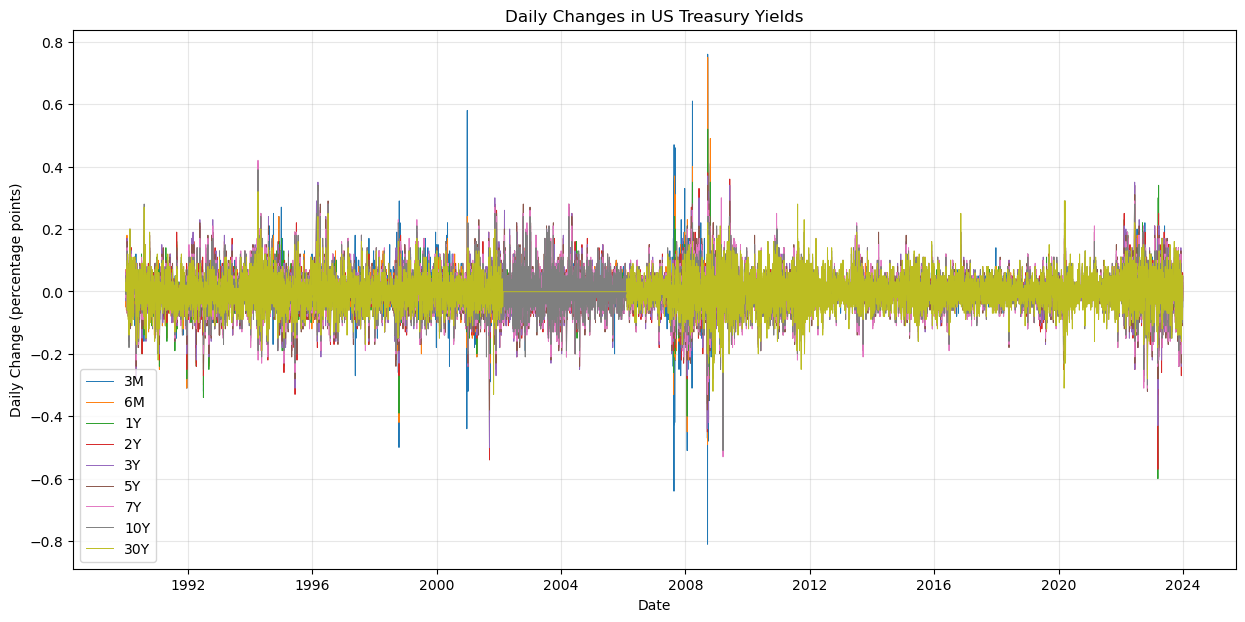

In [12]:
# Plot daily changes in yields
plt.figure(figsize=(15, 7))

for maturity in maturities:
    plt.plot(yield_changes.index, yield_changes[maturity],label=maturity, linewidth=0.7)
plt.title("Daily Changes in US Treasury Yields")
plt.xlabel("Date")
plt.ylabel("Daily Change (percentage points)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5) PCA Application

PCA allows us to transform the nine original variables into a smaller number of independent factors.

Specifically, we want to determine whether most of the movements in the yield curve can be explained by three principal components.

In [13]:
# Apply PCA to daily yield changes without standardisation of maturities

pca_cov = PCA()

# Fit the PCA model
pca_cov.fit(yield_changes)

# Calculate the principal component scores
principal_components = pca_cov.transform(yield_changes)

# Create a df with the principal component
pc_names=["PC"+str(i+1) for i in range (len(maturities))]

df_pc=pd.DataFrame(principal_components,index=yield_changes.index, columns=pc_names)

df_pc.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
date,,,,,,,,,
1990-01-03,0.156205,0.042036,0.013764,-0.006058,-0.009990,-0.010524,0.011023,-0.003862,0.007750
1990-01-04,-0.057127,-0.056319,-0.008824,0.005265,-0.004337,0.001404,0.004029,0.008987,-0.009241
1990-01-05,-0.008686,-0.080538,-0.007009,-0.007269,-0.008387,0.002106,-0.017801,-0.002181,0.000160
1990-01-08,0.044373,-0.000105,0.023347,0.027426,0.014639,-0.002128,0.001447,-0.014789,0.003684
1990-01-09,-0.013850,-0.034575,0.007382,-0.036480,-0.041323,0.013300,0.012284,0.006972,-0.001038


5.1 Variance explanation

In [14]:
# Apply PCA to daily yield changes

pca = PCA()
pca.fit(yield_changes)

# Calculate explained and cumulative variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Create a summary table
pca_summary = pd.DataFrame({
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
}, index=pc_names)

print(pca_summary.round(2))



     Explained Variance (%)  Cumulative Variance (%)
PC1                   77.00                    77.00
PC2                   12.78                    89.78
PC3                    5.21                    94.99
PC4                    2.01                    97.00
PC5                    1.14                    98.14
PC6                    0.77                    98.92
PC7                    0.48                    99.39
PC8                    0.35                    99.74
PC9                    0.26                   100.00


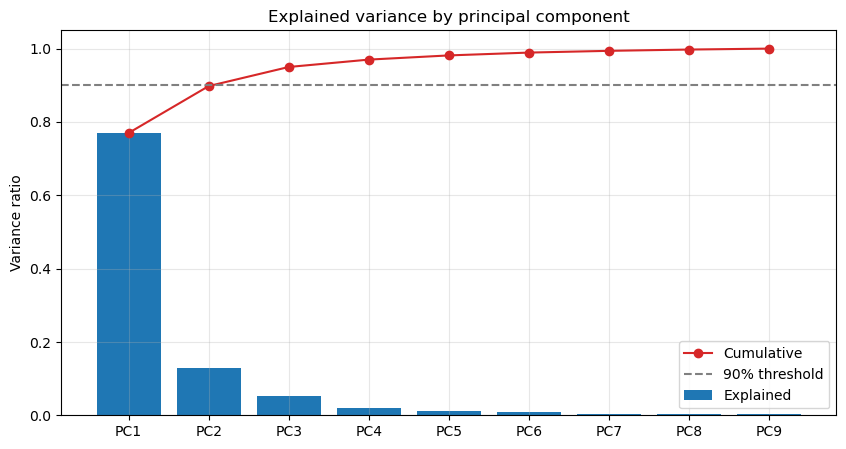

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pc_names, explained_variance, label="Explained")
ax.plot(pc_names, cumulative_variance, marker="o", color="tab:red", label="Cumulative")
ax.axhline(0.90, ls="--", color="gray", label="90% threshold")
ax.set_title("Explained variance by principal component")
ax.set_ylabel("Variance ratio")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

  5.2  Factor loadings: interpretation of the components


A note: the sign of the components is arbitrary. To make the results easier to read, we’ll use the following convention:
- PC1: loadings that are generally positive.
- PC2: loadings that are positive for long maturities relative to short ones.
- PC3: loadings that are positive for intermediate maturities relative to the extreme ones.


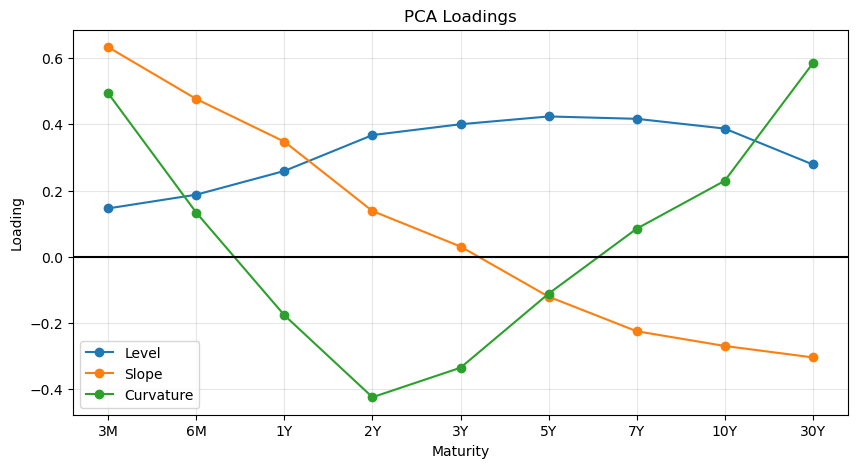

In [16]:

# Calculate the factor loadings

loadings = pd.DataFrame(
    pca.components_.T,
    index=maturities,
    columns=pc_names
)

# Plot the first three principal components

loadings[["PC1", "PC2", "PC3"]].set_axis(
    ["Level", "Slope", "Curvature"], axis=1
).plot(marker="o", figsize=(10, 5))

plt.axhline(0, color="black")
plt.title("PCA Loadings")
plt.xlabel("Maturity")
plt.ylabel("Loading")
plt.grid(alpha=0.3)
plt.show()


The PCA loadings reveal three main factors driving the dynamics of the US Treasury yield curve.

The **first principal component (PC1)**, explaining approximately 77% of total variance, represents the Level factor. Its loadings are positive across all maturities, indicating that yield changes tend to move in the same direction along the entire curve.

The **second principal component (PC2)** represents the Slope factor. Its loadings are positive at short-term maturities and negative at long-term maturities, indicating an opposite movement between the two ends of the yield curve.

An increase in this factor tends to raise short-term yields while reducing long-term yields, resulting in a flattening of the yield curve. Conversely, a decrease in PC2 tends to lower short-term yields and increase long-term yields, producing a steepening of the curve.

The **third principal component (PC3)** represents the Curvature factor, capturing changes in the shape of the curve, particularly movements in intermediate maturities relative to the short and long ends.

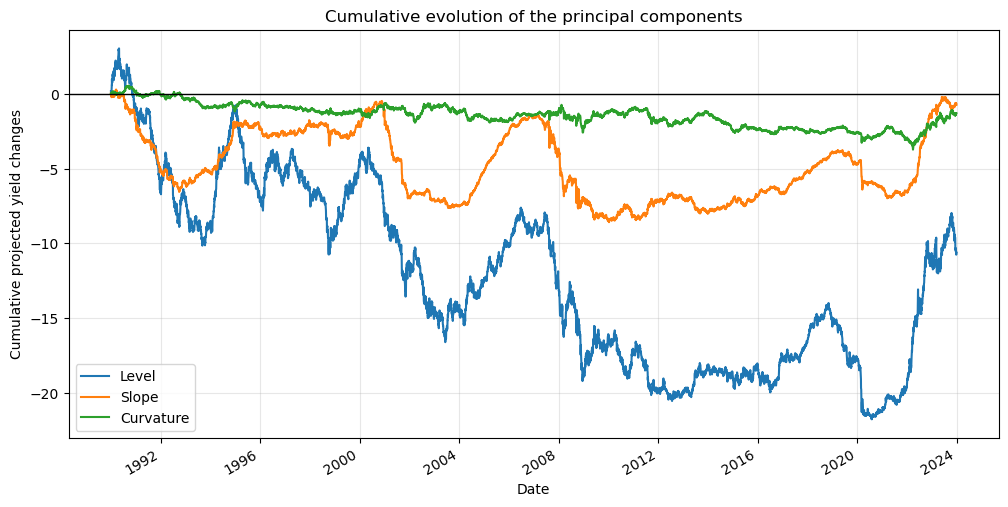

In [17]:

# Cumulative evolution of the principal components

# Extract PCA loadings
comp = pca.components_

# Project daily yield changes onto the principal components
raw_scores = yield_changes.values @ comp.T

# Create dataframe with the first three factors
factor_scores = pd.DataFrame(
    raw_scores[:, :3],
    index=yield_changes.index,
    columns=["Level", "Slope", "Curvature"]
)

# Calculate cumulative factor movements
cum = factor_scores.cumsum()

# Plot
cum.plot(figsize=(12, 6))

plt.axhline(0, color="black", lw=1)
plt.title("Cumulative evolution of the principal components")
plt.xlabel("Date")
plt.ylabel("Cumulative projected yield changes")
plt.grid(alpha=0.3)
plt.show()


The cumulative factor plot provides a complementary perspective by showing how these three factors have evolved over time.

In particular, the cumulative Level factor exhibits a predominantly negative trajectory, reaching approximately -12.94 by the end of 2023. This suggests that the overall movement of US Treasury yields over the sample period has been predominantly downward relative to the initial yield curve in 1990.

The cumulative Slope and Curvature factors instead capture the long-term evolution of the yield curve's steepness and shape.

Overall, the results confirm that changes in the US Treasury yield curve are largely driven by three underlying factors: Level, Slope and Curvature.

# Conclusion

**Dimensionality.** The daily movements of the US Treasury yield curve are concentrated in very few factors. Applying PCA to the covariance matrix of the daily yield changes (nine maturities from 3M to 30Y, 1990-2023), the first component explains 77% of the total variance, the second 13% and the third 5.0%.

**Interpretation of the components.** The loadings have the shapes usually associated with Level, Slope and Curvature (the sign of each component is arbitrary, so we fix a convention):

- **PC1, Level:** all loadings are positive. Yields of all maturities tend to move in the same direction, with the strongest response between 3Y and 10Y and a weaker one at the short end, which is anchored by the policy rate.
- **PC2, Slope:** loadings rise from about -0.6 at 3M to about +0.3 at 30Y and change sign once, close to the 3Y maturity. Short and long yields move in opposite directions: the curve steepens or flattens.
- **PC3, Curvature:** loadings are positive for intermediate maturities (1Y-5Y, peak of about 0.45 at 2Y) and negative at both ends (about -0.5 at 3M and 30Y): the middle of the curve moves against its extremes.

**Cumulative factors.** The cumulative paths follow the main phases of the interest-rate cycle. Level falls in easing phases (early 1990s, 2001, 2008-2012, 2020) and rises in tightening phases (1994, 2022-2023); its final value (about -13) corresponds to an average decline of roughly 4.5 percentage points across maturities over the observed days. Slope reflects monetary policy: the curve steepens when short rates are cut and flattens, or inverts, when they are raised (1994, 1999-2000, 2022-2023). Curvature stays small throughout, in line with its 5% share of variance. 


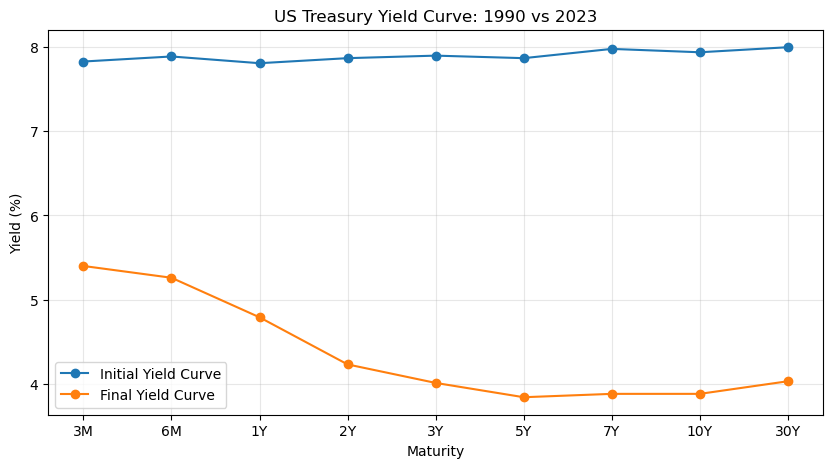

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(maturities, df_clean.iloc[0], marker="o",
         label="Initial Yield Curve")

plt.plot(maturities, df_clean.iloc[-1], marker="o",
         label="Final Yield Curve")

plt.title("US Treasury Yield Curve: 1990 vs 2023")
plt.xlabel("Maturity")
plt.ylabel("Yield (%)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()